# Example of the `aitlas` toolbox in the context of multi label image classification

This notebook shows a sample implementation of a multi label image classification using the `aitlas` toolbox using the DFC15 merced multi label dataset.

In [ ]:
from aitlas.datasets import DFC15MultiLabelDataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/DFC15/train/images", 
    "csv_file": "./data/DFC15/train/multilabels.txt"
    }
dataset = DFC15MultiLabelDataset(dataset_config)
print(len(dataset))

2673


## Show images from the dataset

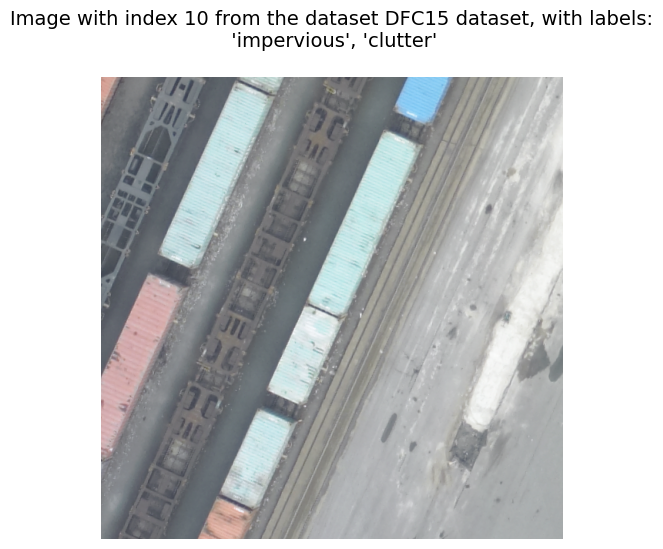

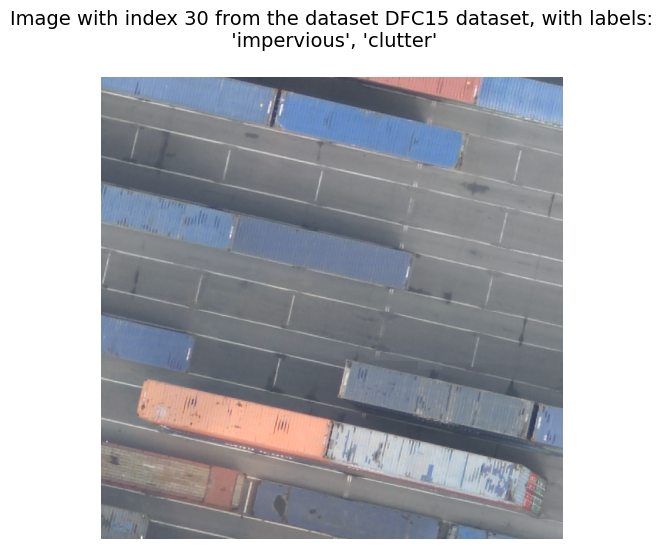

In [12]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(30)

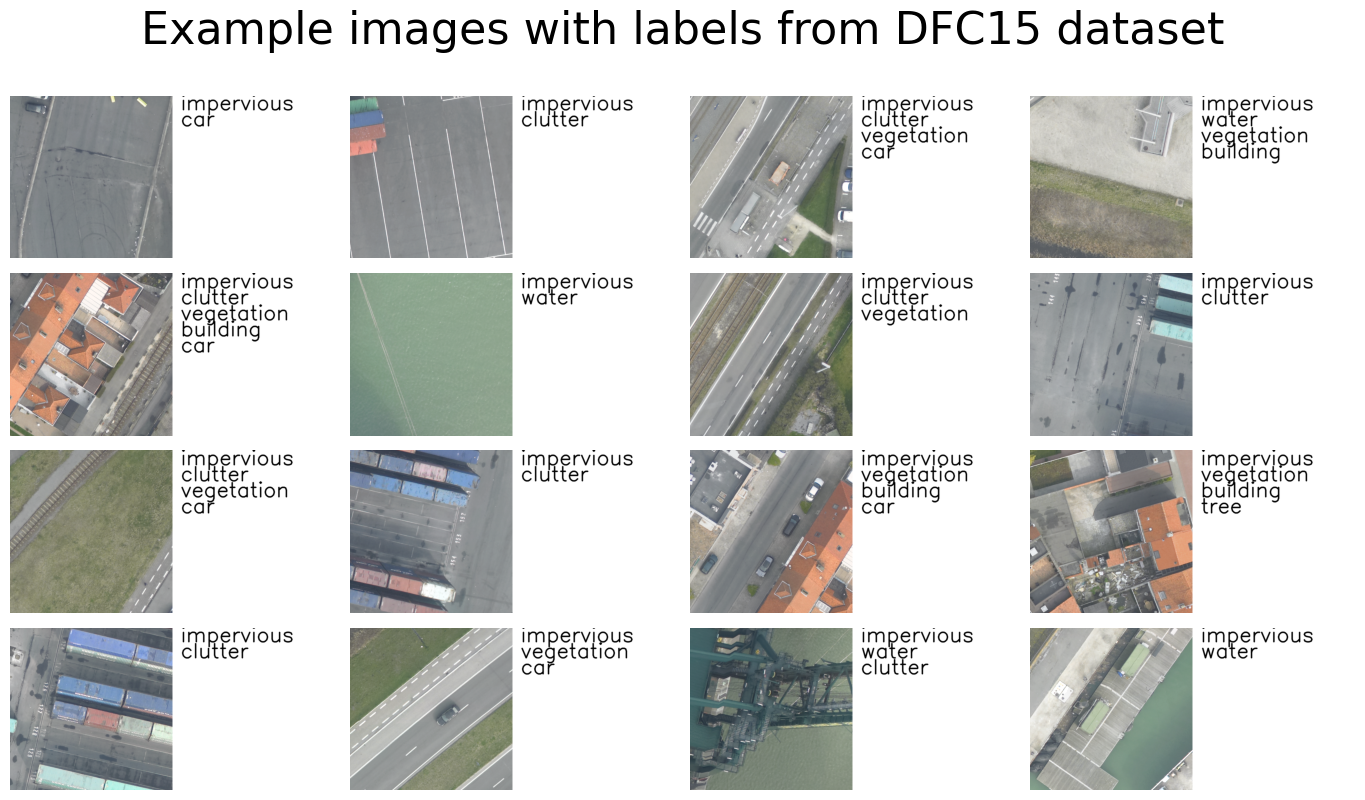

In [14]:
fig3 = dataset.show_batch(16)

## Inspect the data

In [16]:
dataset.data_distribution_table()

,Label,Count
1,impervious,2516
2,water,791
3,clutter,1508
4,vegetation,867
5,building,797
6,tree,201
7,boat,216
8,car,554


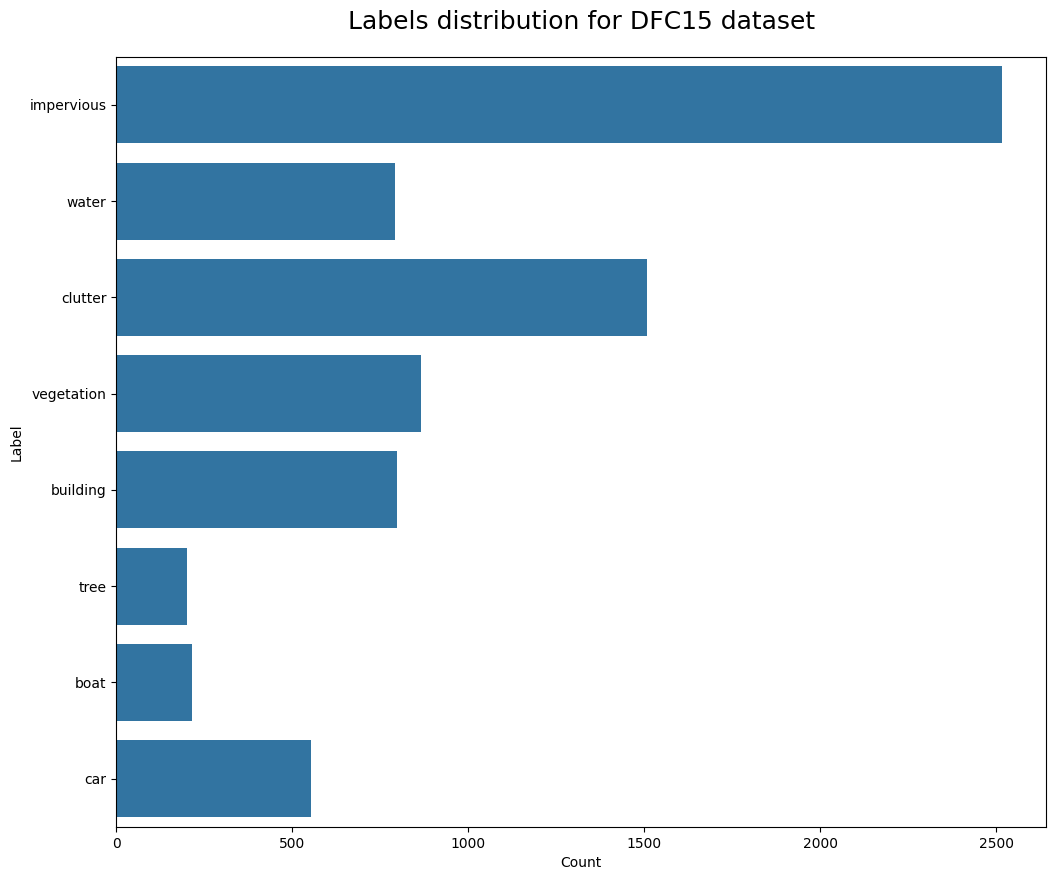

In [17]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/DFC15/train/images",
    "csv_file": "./data/DFC15/train/multilabels.txt",
}

train_dataset = DFC15MultiLabelDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/DFC15/test/images",
    "csv_file": "./data/DFC15/test/multilabels.txt",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = DFC15MultiLabelDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(2673, 669)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/DFC15"
model_config = {
    "num_classes": 8,
    "learning_rate": 0.0001,
    "pretrained": True,
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [20]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 07:27:39,583 INFO Starting training.
training: 100%|██████████| 168/168 [00:11<00:00, 15.17it/s]
2026-08-24 07:27:50,742 INFO epoch: 1, time: 11, loss:  0.46081
testing on train set: 100%|██████████| 168/168 [00:09<00:00, 16.91it/s]
2026-08-24 07:28:01,371 INFO Accuracy:0.9263000374111485, Accuracy per Class:[0.96221474 0.9184437  0.88178077 0.93004115 0.91096147 0.94201272
 0.95959596 0.90534979], Precision Micro:0.9338257016248154, Precision Macro:0.8786490322373773, Precision Weighted:0.9312599598665801, Precision per Class:[0.97859691 0.99311532 0.91971831 0.93367347 0.93333333 0.68852459
 0.78421053 0.7980198 ], Recall Micro:0.8485906040268456, Recall Macro:0.7514511155642604, Recall Weighted:0.8485906040268456, Recall per Class:[0.98131955 0.72945638 0.86604775 0.84429066 0.7553325  0.41791045
 0.68981481 0.72743682], F1_score Micro:0.8891701828410684, F1_score Macro:0.8062546053781103, F1_score Weighted:0.885251982789813, F1_score per Class:[0.97995634 0.84110787 0.89

0.06136547098860361

## Predictions

2026-08-24 07:33:20,103 INFO Loading checkpoint /home/dragik/data/experiments/DFC15/checkpoint.pth.tar
2026-08-24 07:33:20,262 INFO Loaded checkpoint /home/dragik/data/experiments/DFC15/checkpoint.pth.tar at epoch 11


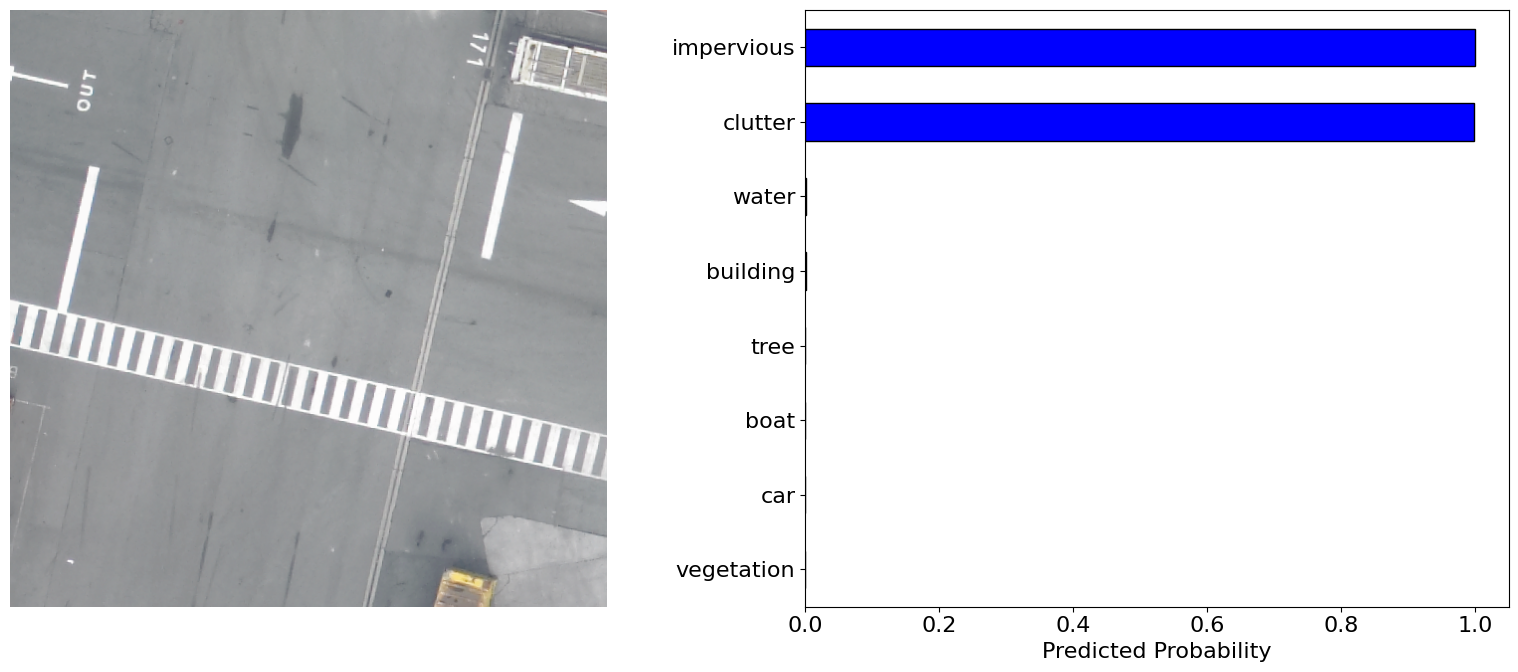

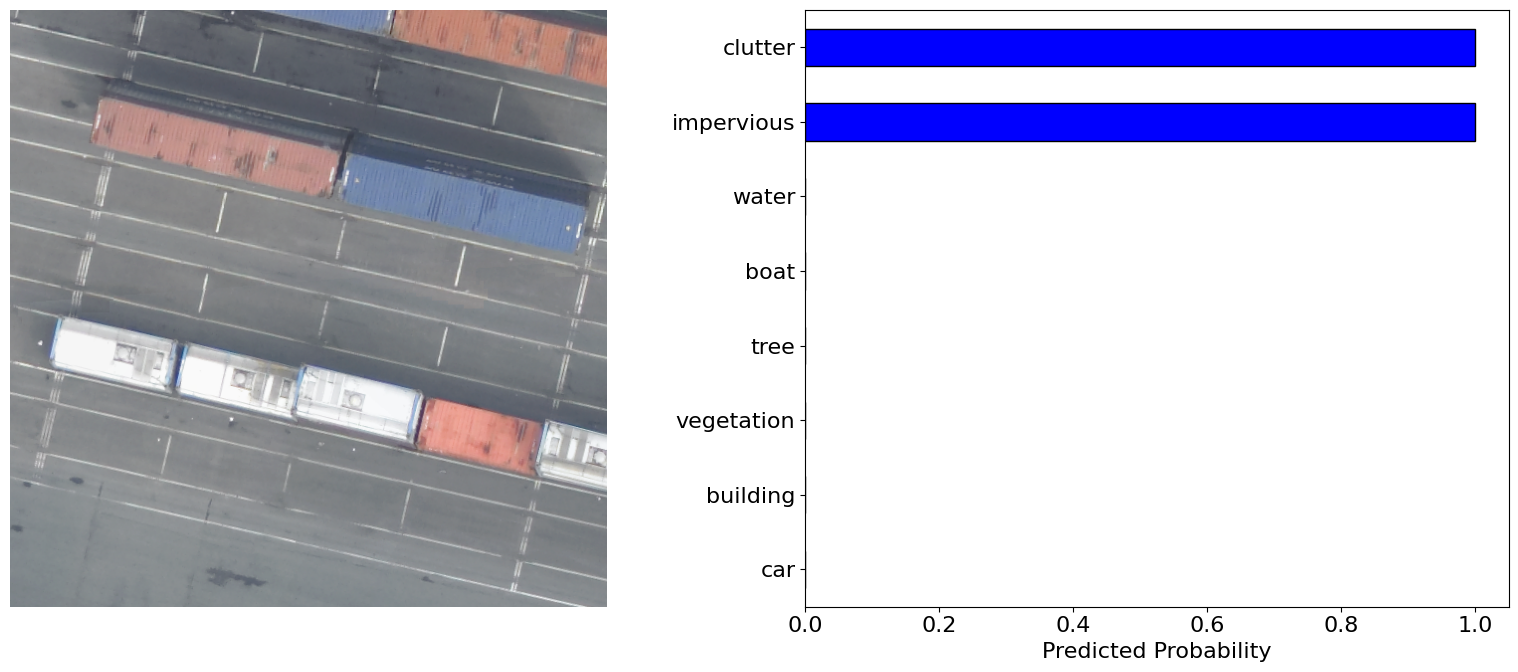

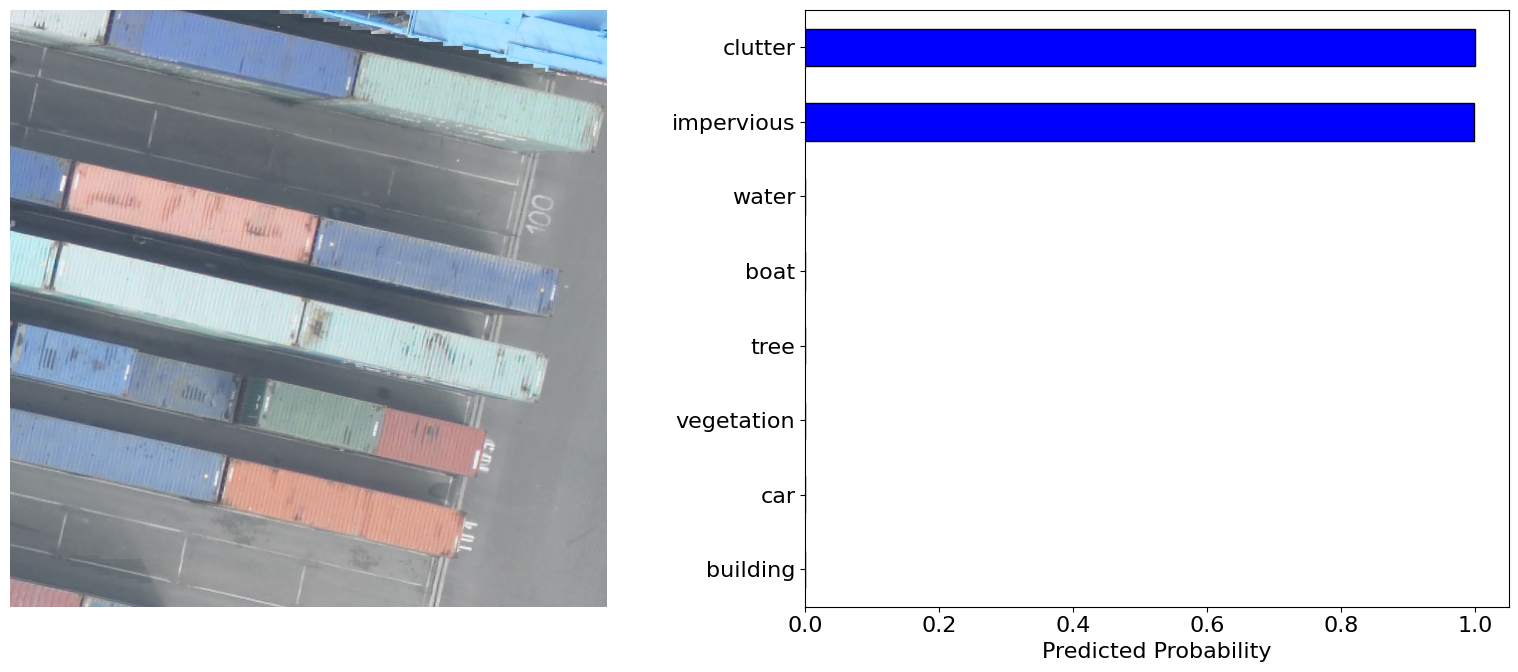

In [ ]:
model_path = "./data/experiments/DFC15/checkpoint.pth.tar"
labels = ["impervious", "water", "clutter", "vegetation", "building", "tree", "boat", "car"]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

image = image_loader("./data/DFC15/test/images/46.png")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/DFC15/test/images/411.png")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/DFC15/test/images/1187.png")
fig = model.predict_image(image, labels, transform)